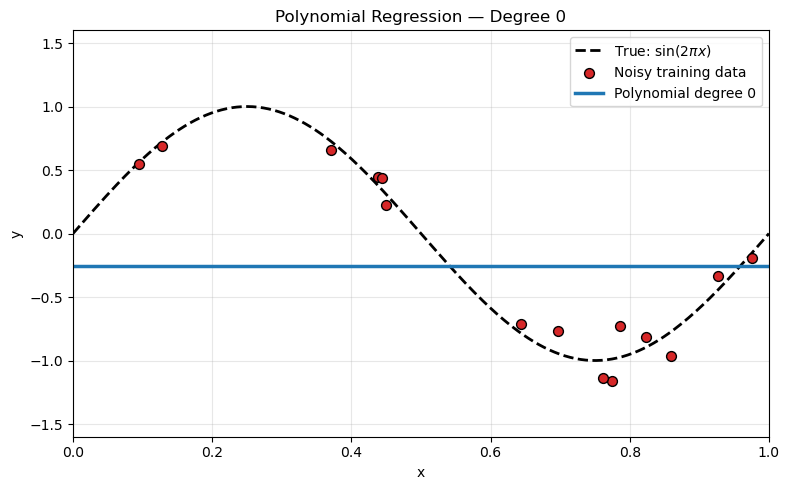

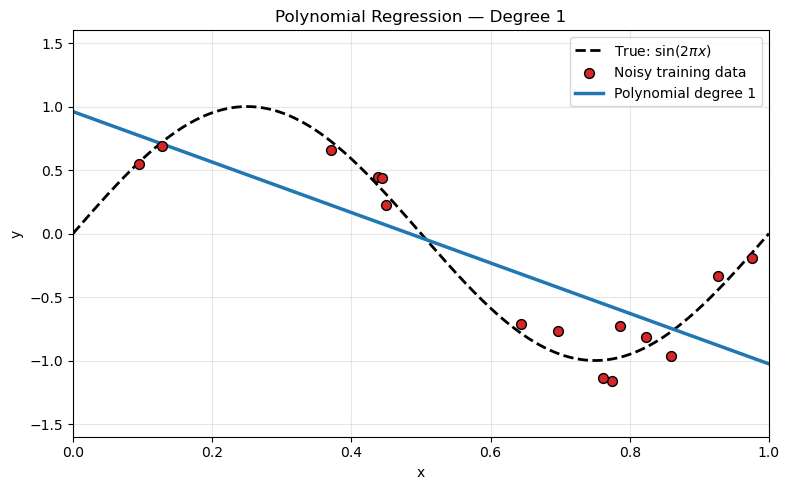

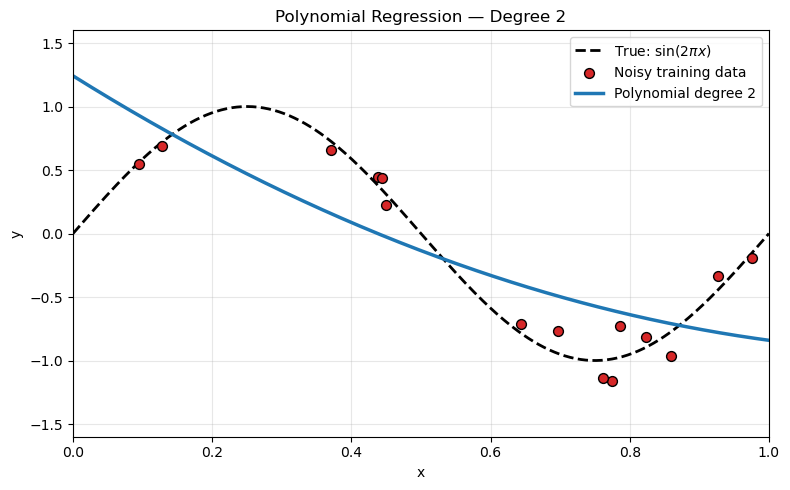

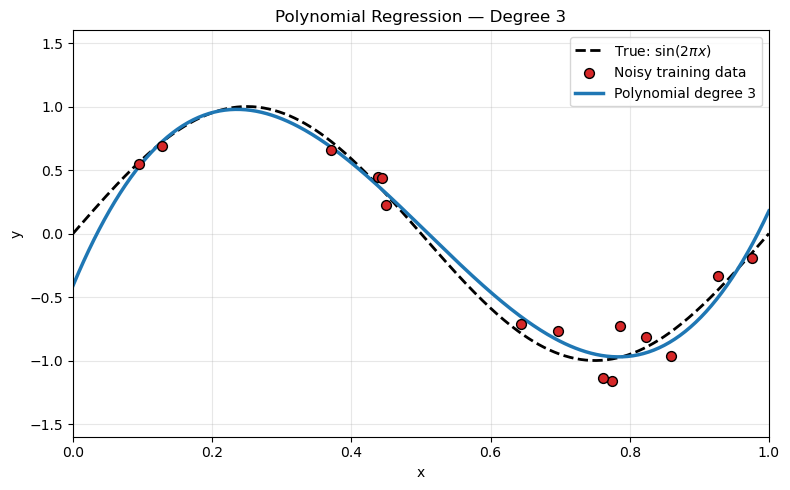

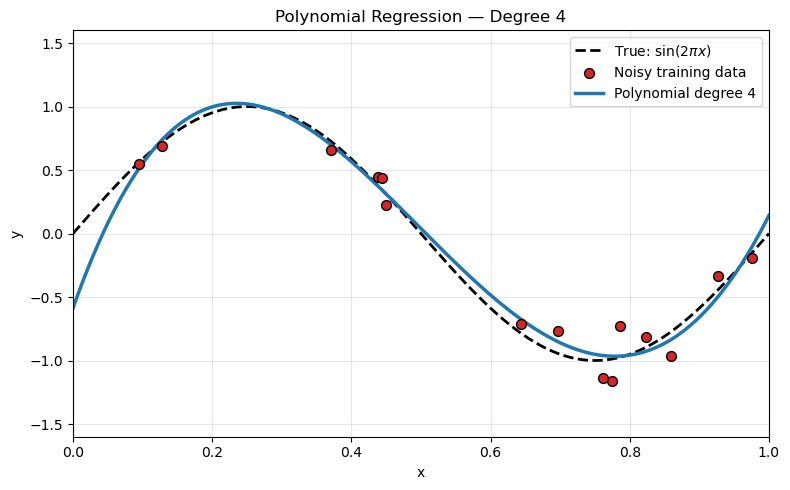

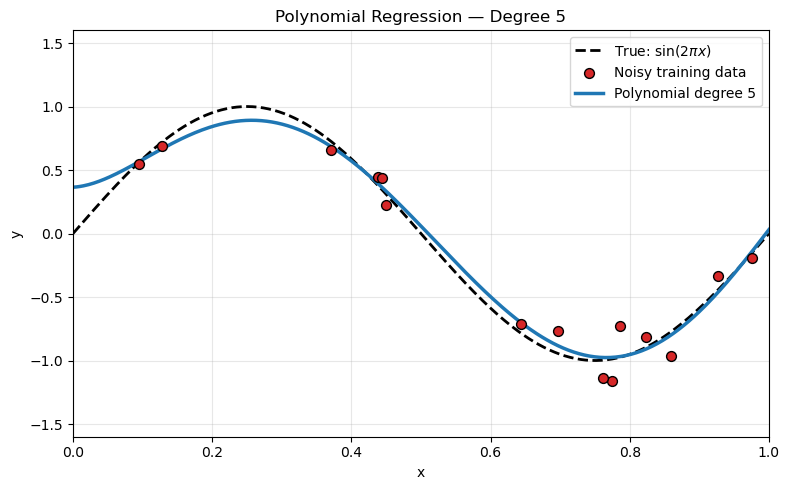

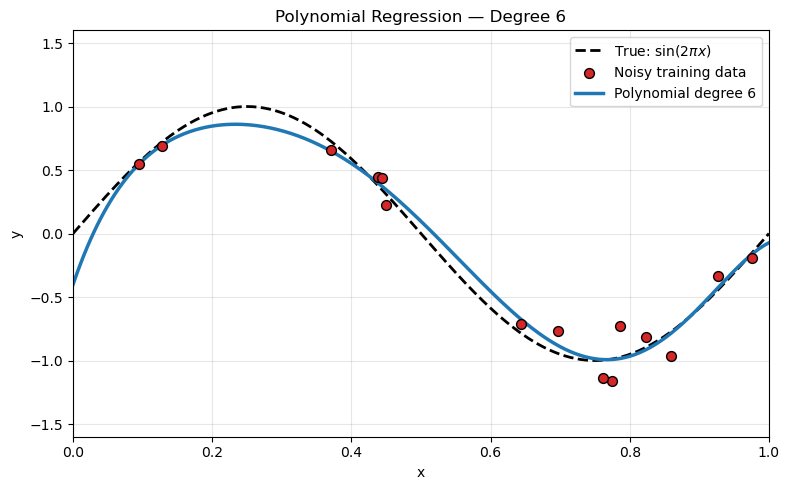

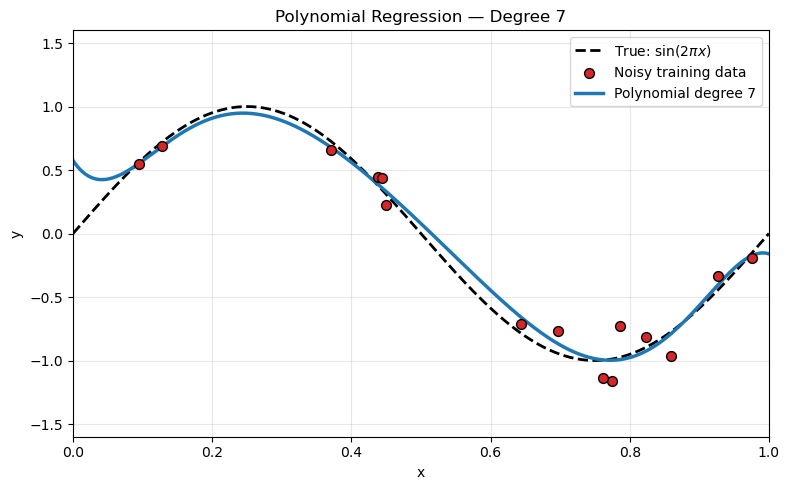

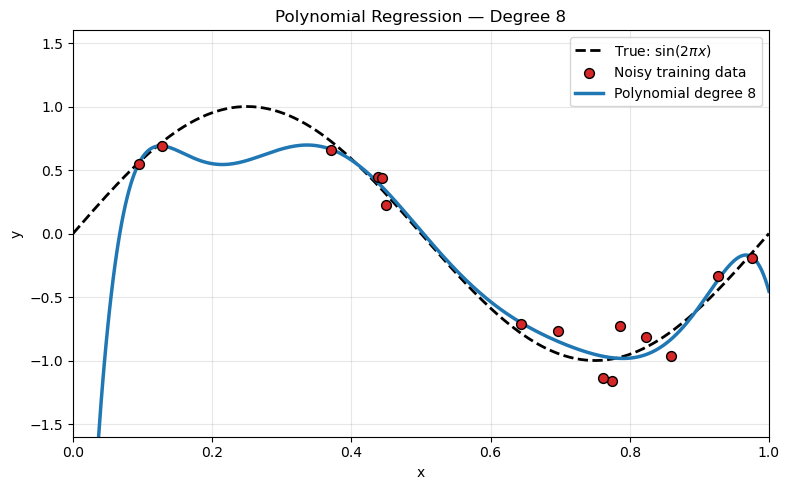

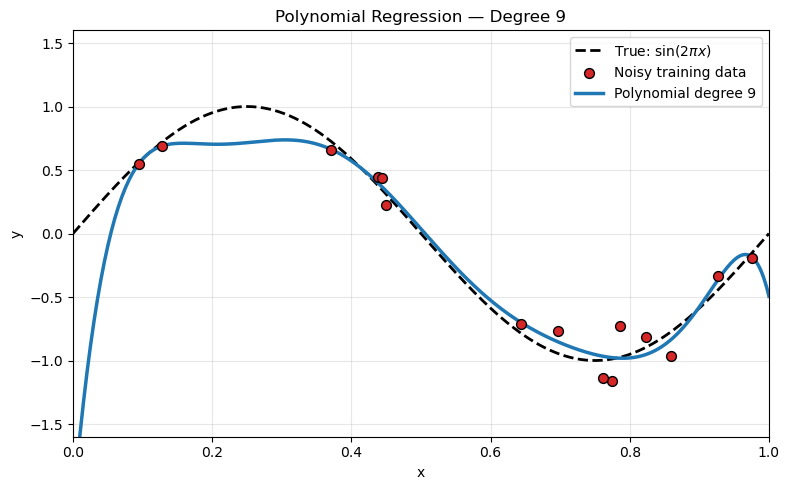

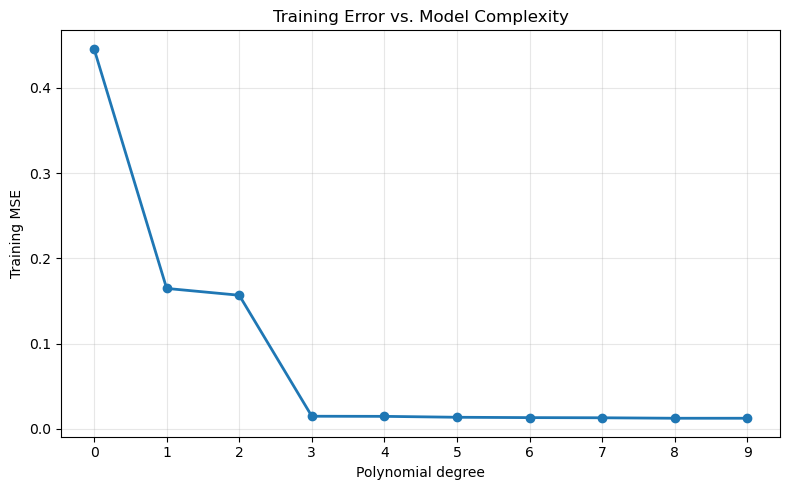

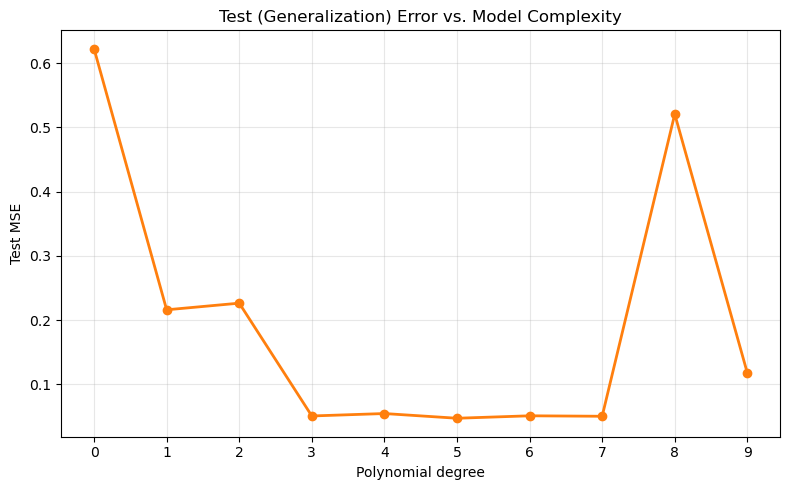

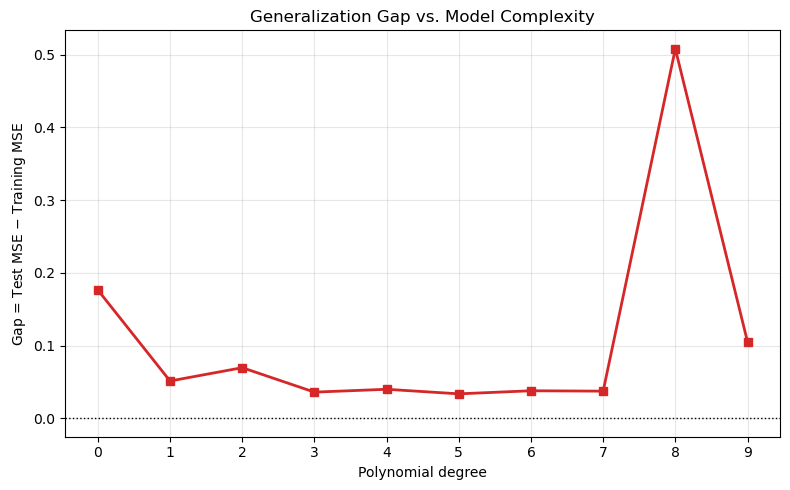

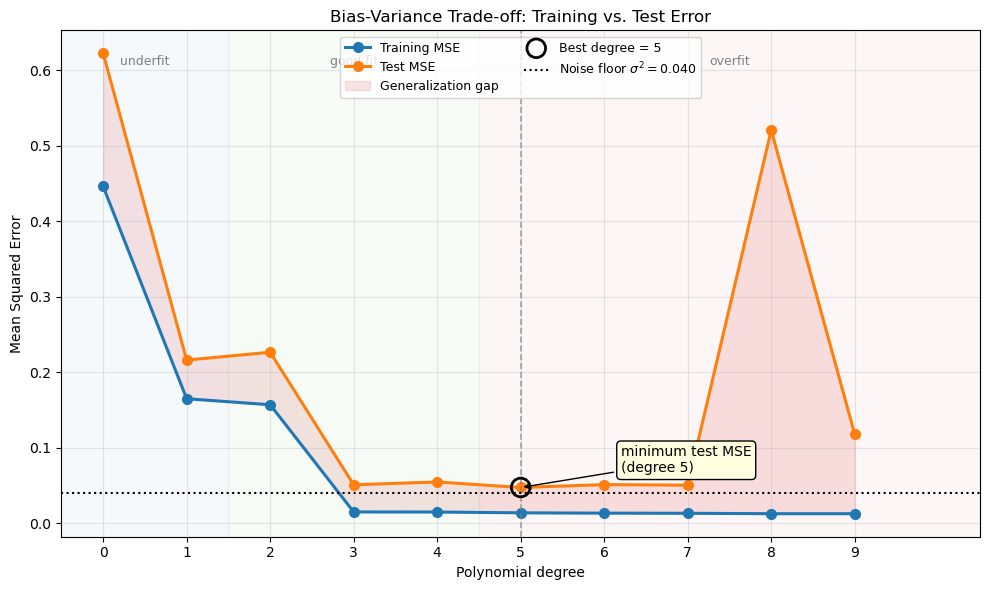

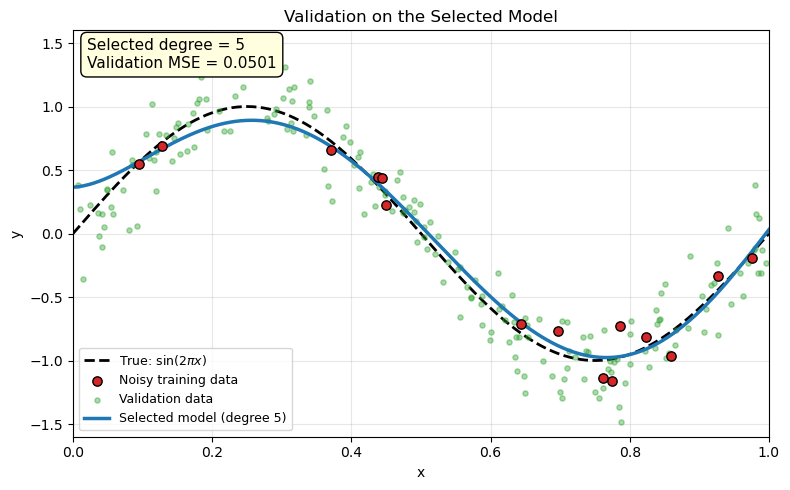


Polynomial Regression — Model Complexity Report
  Degree |   Training MSE |     Test MSE
----------------------------------------
       0 |        0.44582 |      0.62210
       1 |        0.16482 |      0.21603
       2 |        0.15682 |      0.22636
       3 |        0.01493 |      0.05085
       4 |        0.01479 |      0.05462
       5 |        0.01373 |      0.04729
       6 |        0.01332 |      0.05111
       7 |        0.01313 |      0.05038
       8 |        0.01258 |      0.52050
       9 |        0.01257 |      0.11769

  Selected degree (lowest test MSE) : 5
  Training MSE of selected model    : 0.01373
  Test MSE of selected model        : 0.04729
  Validation MSE of selected model  : 0.05015

Educational interpretation:
  * Low degrees   -> underfitting (high train & test error).
  * Mid degrees   -> good fit (both errors small).
  * High degrees  -> overfitting (train error tiny, test error grows).
  * Gap = Test - Train grows with model complexity.


In [4]:
# =============================================================================
# MODEL COMPLEXITY AND POLYNOMIAL REGRESSION
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting on a
# noisy sine wave using polynomial regression of degrees 0 through 10.
#
# Data model:
#     y = sin(2 * pi * x) + eps,   eps ~ N(0, sigma^2),   x in [0, 1]
#
# Figures produced:
#   1. 11 fitting plots (degree = 0, 1, ..., 10)
#   2. Training MSE vs. degree
#   3. Test MSE vs. degree  (U-shaped)
#   4. Generalization gap = Test MSE - Training MSE
#   5. Validation error of the selected model
#   6. Combined Training & Test MSE vs. degree   <-- NEW
#
# Console output:
#   Table of (degree, training MSE, test MSE)
#   Best degree by test error, with training, test, and validation MSE.
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error


# =============================================================================
# 1. REPRODUCIBILITY
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TRAIN = 15
N_TEST = 200
N_VALID = 200

NOISE_SIGMA = 0.20
DEGREES = list(range(0, 10))


# =============================================================================
# 2. TRUE FUNCTION AND DATA GENERATION
# =============================================================================
def true_function(x):
    """Underlying ground-truth function y = sin(2*pi*x)."""
    return np.sin(2.0 * np.pi * x)


def sample_points(n, rng):
    """Return n points uniformly in [0, 1] plus their noisy targets."""
    x = rng.uniform(0.0, 1.0, size=n).reshape(-1, 1)
    y = true_function(x.ravel()) + rng.normal(0.0, NOISE_SIGMA, size=n)
    return x, y


X_train, y_train = sample_points(N_TRAIN, rng)
X_test, y_test = sample_points(N_TEST, rng)
X_valid, y_valid = sample_points(N_VALID, rng)

X_grid = np.linspace(0.0, 1.0, 400).reshape(-1, 1)
y_grid_true = true_function(X_grid.ravel())


# =============================================================================
# 3. MODEL FITTING
# =============================================================================
def make_pipeline(degree):
    """Polynomial regression pipeline: expand -> linear fit."""
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("linreg", LinearRegression(fit_intercept=False)),
    ])


def fit_and_evaluate(degree):
    """Fit a degree-d polynomial on the training set and return the model
    plus MSEs on train and test."""
    model = make_pipeline(degree)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    mse_train = mean_squared_error(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)
    return model, mse_train, mse_test


# =============================================================================
# 4. INDIVIDUAL FIT PLOTS
# =============================================================================
def plot_fit(degree, model):
    y_grid_pred = model.predict(X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2, label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=50, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=f"Polynomial degree {degree}")

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Polynomial Regression — Degree {degree}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.savefig(f"fit_degree_{degree:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 5. FIT ALL DEGREES
# =============================================================================
def fit_all_degrees(degrees):
    results = {}
    for d in degrees:
        model, mse_train, mse_test = fit_and_evaluate(d)
        results[d] = {
            "model": model,
            "mse_train": mse_train,
            "mse_test": mse_test,
        }
        plot_fit(d, model)
    return results


results = fit_all_degrees(DEGREES)

degrees = np.array(DEGREES)
mse_train = np.array([results[d]["mse_train"] for d in degrees])
mse_test = np.array([results[d]["mse_test"] for d in degrees])
gap = mse_test - mse_train


# =============================================================================
# 6. TRAINING ERROR vs. DEGREE
# =============================================================================
def plot_train_error(degrees, mse_train):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(degrees, mse_train, "-o", lw=2, color="tab:blue")
    ax.set_xlabel("Polynomial degree")
    ax.set_ylabel("Training MSE")
    ax.set_title("Training Error vs. Model Complexity")
    ax.set_xticks(degrees)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("training_error_vs_degree.png", dpi=120)
    plt.show()


# =============================================================================
# 7. TEST ERROR vs. DEGREE
# =============================================================================
def plot_test_error(degrees, mse_test):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(degrees, mse_test, "-o", lw=2, color="tab:orange")
    ax.set_xlabel("Polynomial degree")
    ax.set_ylabel("Test MSE")
    ax.set_title("Test (Generalization) Error vs. Model Complexity")
    ax.set_xticks(degrees)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("test_error_vs_degree.png", dpi=120)
    plt.show()


# =============================================================================
# 8. GENERALIZATION GAP
# =============================================================================
def plot_gap(degrees, gap):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(degrees, gap, "-s", lw=2, color="tab:red")
    ax.axhline(0.0, color="black", lw=1, linestyle=":")
    ax.set_xlabel("Polynomial degree")
    ax.set_ylabel(r"Gap = Test MSE $-$ Training MSE")
    ax.set_title("Generalization Gap vs. Model Complexity")
    ax.set_xticks(degrees)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("generalization_gap_vs_degree.png", dpi=120)
    plt.show()


# =============================================================================
# 9. COMBINED TRAINING & TEST ERROR
# =============================================================================
def plot_train_test_combined(degrees, mse_train, mse_test,
                             best_degree=None, noise_sigma=None):
    """Show training and test MSE on the same axes.

    Visualizes the bias-variance trade-off:
      * Training error keeps decreasing with degree (bias decreases).
      * Test error is U-shaped: high at low degree (bias) and high at
        high degree (variance).
      * The vertical distance between the two curves is the generalization gap.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # --- Curves ---
    ax.plot(degrees, mse_train, "-o", lw=2.2, color="tab:blue",
            markersize=7, label="Training MSE")
    ax.plot(degrees, mse_test, "-o", lw=2.2, color="tab:orange",
            markersize=7, label="Test MSE")

    # --- Shade the gap between the curves ---
    ax.fill_between(degrees, mse_train, mse_test,
                    where=(mse_test >= mse_train),
                    color="tab:red", alpha=0.12,
                    label="Generalization gap")
    ax.fill_between(degrees, mse_test, mse_train,
                    where=(mse_train > mse_test),
                    color="tab:green", alpha=0.12)

    # --- Highlight the optimum ---
    if best_degree is not None:
        best_idx = int(np.where(degrees == best_degree)[0][0])
        ax.axvline(best_degree, color="gray", lw=1.2, linestyle="--",
                   alpha=0.7)
        ax.scatter([best_degree], [mse_test[best_idx]],
                   s=180, facecolor="none", edgecolor="black",
                   linewidth=2, zorder=5,
                   label=f"Best degree = {best_degree}")
        ax.annotate(
            f"minimum test MSE\n(degree {best_degree})",
            xy=(best_degree, mse_test[best_idx]),
            xytext=(best_degree + 1.2, mse_test[best_idx] + 0.02),
            fontsize=10,
            arrowprops=dict(arrowstyle="->", color="black", lw=1),
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor="lightyellow", edgecolor="black"),
        )

    # --- Reference: irreducible noise level ---
    if noise_sigma is not None:
        ax.axhline(noise_sigma ** 2, color="k", linestyle=":", lw=1.5,
                   label=rf"Noise floor $\sigma^2 = {noise_sigma**2:.3f}$")

    # --- Regime bands (visual hints) ---
    ax.axvspan(-0.5, 1.5, color="tab:blue", alpha=0.04)
    ax.axvspan(1.5, 4.5, color="tab:green", alpha=0.04)
    ax.axvspan(4.5, 10.5, color="tab:red", alpha=0.04)
    ax.text(0.5, ax.get_ylim()[1] * 0.95, "underfit",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(3.0, ax.get_ylim()[1] * 0.95, "good fit",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(7.5, ax.get_ylim()[1] * 0.95, "overfit",
            ha="center", va="top", fontsize=9, color="gray")

    # --- Cosmetics ---
    ax.set_xlim(-0.5, 10.5)
    ax.set_xticks(degrees)
    ax.set_xlabel("Polynomial degree")
    ax.set_ylabel("Mean Squared Error")
    ax.set_title("Bias-Variance Trade-off: Training vs. Test Error")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper center", ncol=2, fontsize=9)

    plt.tight_layout()
    plt.savefig("train_test_error_combined.png", dpi=120)
    plt.show()


# =============================================================================
# 10. VALIDATION ON THE SELECTED MODEL
# =============================================================================
def plot_validation(selected_degree, model, mse_valid):
    y_grid_pred = model.predict(X_grid)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(X_grid, y_grid_true, "k--", lw=2,
            label=r"True: $\sin(2\pi x)$")
    ax.scatter(X_train, y_train, s=45, c="tab:red", edgecolor="black",
               zorder=3, label="Noisy training data")
    ax.scatter(X_valid, y_valid, s=14, c="tab:green", alpha=0.4,
               zorder=2, label="Validation data")
    ax.plot(X_grid, y_grid_pred, "tab:blue", lw=2.5,
            label=f"Selected model (degree {selected_degree})")

    ax.annotate(
        f"Selected degree = {selected_degree}\n"
        f"Validation MSE = {mse_valid:.4f}",
        xy=(0.02, 0.98), xycoords="axes fraction",
        ha="left", va="top", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="lightyellow", edgecolor="black"),
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Validation on the Selected Model")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    plt.savefig("validation_selected_model.png", dpi=120)
    plt.show()


# =============================================================================
# 11. REPORTING
# =============================================================================
def print_table(degrees, mse_train, mse_test):
    header = f"{'Degree':>8} | {'Training MSE':>14} | {'Test MSE':>12}"
    print(header)
    print("-" * len(header))
    for d, mtr, mte in zip(degrees, mse_train, mse_test):
        print(f"{d:>8d} | {mtr:>14.5f} | {mte:>12.5f}")


def select_best_degree(degrees, mse_test):
    idx = int(np.argmin(mse_test))
    return int(degrees[idx])


# =============================================================================
# 12. MAIN
# =============================================================================
def main():
    # ---- Summary figures ----
    plot_train_error(degrees, mse_train)
    plot_test_error(degrees, mse_test)
    plot_gap(degrees, gap)

    # ---- NEW: combined training + test error ----
    best_degree = select_best_degree(degrees, mse_test)
    plot_train_test_combined(
        degrees, mse_train, mse_test,
        best_degree=best_degree,
        noise_sigma=NOISE_SIGMA,
    )

    # ---- Validation on the selected model ----
    best_model = results[best_degree]["model"]
    y_valid_pred = best_model.predict(X_valid)
    mse_valid = mean_squared_error(y_valid, y_valid_pred)
    plot_validation(best_degree, best_model, mse_valid)

    # ---- Console report ----
    print()
    print("=" * 50)
    print("Polynomial Regression — Model Complexity Report")
    print("=" * 50)
    print_table(degrees, mse_train, mse_test)

    print()
    print(f"  Selected degree (lowest test MSE) : {best_degree}")
    print(f"  Training MSE of selected model    : {mse_train[best_degree]:.5f}")
    print(f"  Test MSE of selected model        : {mse_test[best_degree]:.5f}")
    print(f"  Validation MSE of selected model  : {mse_valid:.5f}")

    print()
    print("Educational interpretation:")
    print("  * Low degrees   -> underfitting (high train & test error).")
    print("  * Mid degrees   -> good fit (both errors small).")
    print("  * High degrees  -> overfitting (train error tiny, test error grows).")
    print("  * Gap = Test - Train grows with model complexity.")


if __name__ == "__main__":
    main()